# Attacking Creator Recruitment Analysis | 2024/25

**Tools:** Python, SQL (DuckDB), pandas, Matplotlib

## Recruitment question

Which attacking creators from Europe's five major leagues demonstrated the strongest combination of chance creation and goal threat during the 2024/25 season?

The purpose of this analysis is to narrow a broad player pool into a smaller group for further scouting. It is a statistical screening exercise, not a recommendation to sign a particular player.

## Approach

The analysis uses Understat player-season data from the Premier League, La Liga, Bundesliga, Serie A, and Ligue 1.

Player performance is compared using expected assists (xA), key passes, non-penalty expected goals (npxG), and expected goals buildup (xG buildup), normalized per 90 minutes.

The initial analysis requires 1,200 minutes of playing time. A stricter 1,800-minute threshold is subsequently applied to test the shortlist's consistency across three recruitment priorities.

Because the source uses broad positional categories, the player pool includes central midfielders, attacking midfielders, and wide creators.

## Data source

- [Understat](https://understat.com/) — underlying player statistics
- [Understat Players Aggregated](https://github.com/vibedatascience/understat_players_aggregated) — public third-party dataset

This analysis uses the completed 2024/25 season. Club affiliations refer to that season rather than current transfer status.

## 1. Load data and inspect the columns



In [21]:
!pip -q install duckdb

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)


DATA_URL = (
    'https://raw.githubusercontent.com/vibedatascience/'
    'understat_players_aggregated/'
    '768b7ca0b977a5e6b4b429c7b0cf750e8269f2fc/'
    'understat_players_aggregated_2014_2024.csv'
)


players_raw = pd.read_csv(DATA_URL)
print(f'Loaded {len(players_raw):,} player-season/team records across {len(players_raw.columns)} columns.')
print('Columns:')
print(players_raw.columns.tolist())
display(players_raw.head(5))

Loaded 34,815 player-season/team records across 23 columns.
Columns:
['assists', 'games', 'goals', 'id', 'key_passes', 'npg', 'npxG', 'player_name', 'position', 'red_cards', 'shots', 'team_title', 'time', 'xA', 'xG', 'xGBuildup', 'xGChain', 'yellow_cards', 'league', 'year', 'scrape_timestamp', 'primary_position', 'season']


,assists,games,goals,id,key_passes,npg,npxG,player_name,position,red_cards,shots,team_title,time,xA,xG,xGBuildup,xGChain,yellow_cards,league,year,scrape_timestamp,primary_position,season
0,8,33,26,619,33,21,20.703195,Sergio Agüero,F S,0,148,Manchester City,2551,5.568927,25.270176,6.878170,27.805153,4,EPL,2014,2025-09-01 14:25:09.309969,F,2014/15
1,4,34,21,647,27,19,14.873822,Harry Kane,F M S,0,112,Tottenham,2589,3.922502,17.157300,5.549699,16.488435,4,EPL,2014,2025-09-01 14:25:09.309969,F,2014/15
2,3,26,20,802,41,19,14.457944,Diego Costa,F S,0,76,Chelsea,2111,4.554671,15.219113,5.276973,21.365790,8,EPL,2014,2025-09-01 14:25:09.309969,F,2014/15
3,5,35,18,848,23,15,14.076048,Charlie Austin,F,1,131,Queens Park Rangers,3078,2.548746,17.881857,3.041320,13.718285,4,EPL,2014,2025-09-01 14:25:09.309969,F,2014/15
4,8,35,16,498,82,16,12.690581,Alexis Sánchez,F M S,0,122,Arsenal,2967,8.494181,13.451748,10.736757,27.157570,4,EPL,2014,2025-09-01 14:25:09.309969,F,2014/15


## 2. Data quality audit

Before ranking players, verify the expected columns and check the dataset's coverage. Because transfers can create multiple player/team records in one season, **player names are not reliable join or grouping keys**; we use the source's `id` instead.

In [22]:
required = {
    'id','player_name','team_title','league','year','season',
    'primary_position','time','key_passes','xA','npxG','xGBuildup'
}
missing = required - set(players_raw.columns)
if missing:
    raise ValueError(f'Missing expected dataset fields: {sorted(missing)}')

print('Null values in essential fields:')
display(players_raw[list(sorted(required))].isna().sum().sort_values(ascending=False).to_frame('null_count'))
print('Seasons available (last ten):')
display(players_raw.groupby(['year','season'], dropna=False).size().tail(10).to_frame('records'))
print('Available position labels:')
display(players_raw['primary_position'].value_counts(dropna=False).to_frame('records'))
print('Exact duplicate source records:', players_raw.duplicated().sum())

# Convert columns that may arrive as strings in exported data.
for col in ['time','key_passes','xA','npxG','xGBuildup']:
    players_raw[col] = pd.to_numeric(players_raw[col], errors='coerce')

print('Records in selected season:', (players_raw['year'] == 2024).sum())

Null values in essential fields:


,null_count
id,0
key_passes,0
league,0
npxG,0
player_name,0
primary_position,0
season,0
team_title,0
time,0
xA,0


Seasons available (last ten):


,,records
year,season,
2015,2015/16,3114
2016,2016/17,3111
2017,2017/18,3056
2018,2018/19,3019
2019,2019/20,3140
2020,2020/21,3241
2021,2021/22,3324
2022,2022/23,3288
2023,2023/24,3238


Available position labels:


,records
primary_position,
D,12888
F,8165
M,7449
S,3744
GK,2569


Exact duplicate source records: 0
Records in selected season: 3240


## 3. Define the Scouting Sample with SQL

**Initial case study:** The analysis evaluates attacking creators classified as midfielders in the source dataset. We select players coded as midfielders by the dataset, across five European leagues, from the complete **2024/25** season. This broad `M` tag does **not** distinguish defensive, central, and attacking midfield roles; scouting staff would still need to review playing positions and tactical responsibilities.

**Sample threshold:** At least **1,200 minutes**. We use a modest threshold to reduce unstable per-90 estimates from tiny samples, but recognize that it excludes some promising substitutes and injured players.

**Transfers:** A player may appear for multiple clubs. This query first aggregates records by player ID, season, and league; their minutes and events are combined within a league. A player who appeared in two different leagues that season may have two rows and should be reviewed individually before recommending a transfer.

In [23]:
SEASON_START = 2024          # 2024/25
MIN_MINUTES = 1200
LEAGUES = ['EPL', 'La_Liga', 'Bundesliga', 'Serie_A', 'Ligue_1']

con = duckdb.connect()
con.register('source_players', players_raw)

scouting = con.execute("""
    WITH player_season AS (
        SELECT
            id AS player_id,
            MIN(player_name) AS player_name,
            STRING_AGG(DISTINCT team_title, ' / ') AS clubs,
            league,
            season,
            SUM("time") AS minutes,
            SUM(key_passes) AS key_passes,
            SUM(xA) AS xa,
            SUM(npxG) AS npxg,
            SUM(xGBuildup) AS xg_buildup
        FROM source_players
        WHERE year = ?
          AND league IN (?, ?, ?, ?, ?)
          AND primary_position = 'M'
        GROUP BY id, league, season
    )
    SELECT
        *,
        ROUND(90.0 * key_passes / NULLIF(minutes, 0), 3) AS key_passes_p90,
        ROUND(90.0 * xa / NULLIF(minutes, 0), 3) AS xa_p90,
        ROUND(90.0 * npxg / NULLIF(minutes, 0), 3) AS npxg_p90,
        ROUND(90.0 * xg_buildup / NULLIF(minutes, 0), 3) AS xg_buildup_p90
    FROM player_season
    WHERE minutes >= ?
    ORDER BY xa_p90 DESC, minutes DESC
""", [SEASON_START, *LEAGUES, MIN_MINUTES]).df()

print(f'{len(scouting):,} qualifying player-league records')
display(scouting.head(15))

282 qualifying player-league records


,player_id,player_name,clubs,league,season,minutes,key_passes,xa,npxg,xg_buildup,key_passes_p90,xa_p90,npxg_p90,xg_buildup_p90
0,9948,Michael Olise,Bayern Munich,Bundesliga,2024/25,2370.0,89.0,14.287162,10.028208,15.147963,3.380,0.543,0.381,0.575
1,2250,Luka Modric,Real Madrid,La_Liga,2024/25,1774.0,66.0,7.897418,1.616865,15.646373,3.348,0.401,0.082,0.794
2,6756,Dwight McNeil,Everton,EPL,2024/25,1374.0,37.0,6.039636,1.512262,3.559031,2.424,0.396,0.099,0.233
3,8497,Cole Palmer,Chelsea,EPL,2024/25,3228.0,87.0,12.954366,11.968392,9.802262,2.426,0.361,0.334,0.273
4,11822,Fermín López,Barcelona,La_Liga,2024/25,1224.0,29.0,4.712301,4.756552,7.853521,2.132,0.346,0.350,0.577
5,261,Julian Brandt,Borussia Dortmund,Bundesliga,2024/25,2354.0,61.0,9.031146,4.579855,13.325243,2.332,0.345,0.175,0.509
6,337,Leroy Sané,Bayern Munich,Bundesliga,2024/25,1638.0,37.0,6.123259,10.864086,8.566131,2.033,0.336,0.597,0.471
7,189,Hakan Calhanoglu,Inter,Serie_A,2024/25,1999.0,49.0,7.045006,1.369010,11.181229,2.206,0.317,0.062,0.503
8,10058,Maghnes Akliouche,Monaco,Ligue_1,2024/25,2419.0,47.0,8.499506,7.522183,11.500963,1.749,0.316,0.280,0.428
9,1055,Aleix García,Bayer Leverkusen,Bundesliga,2024/25,1438.0,32.0,5.045785,0.849897,4.544854,2.003,0.316,0.053,0.284


## 4. Explore the trade-off: creativity vs. scoring threat

Expected assists and non-penalty expected goals reflect different contributions. A midfield recruitment shortlist should not reward goalscoring alone if the coach actually needs a player who creates chances for teammates.

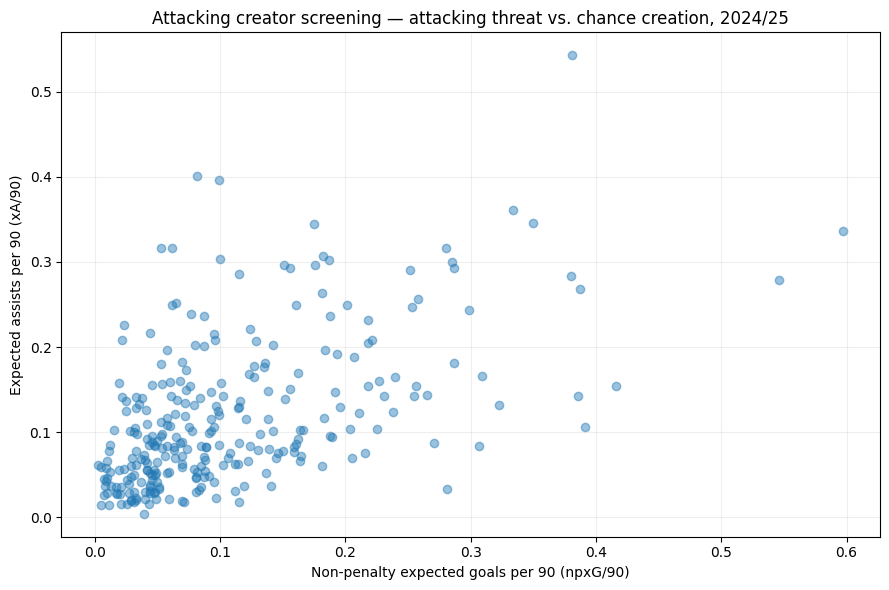

Top 10 by expected assists per 90 (not the final shortlist):


,player_name,clubs,league,minutes,xa_p90,key_passes_p90,npxg_p90
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,0.543,3.380,0.381
1,Luka Modric,Real Madrid,La_Liga,1774.0,0.401,3.348,0.082
2,Dwight McNeil,Everton,EPL,1374.0,0.396,2.424,0.099
3,Cole Palmer,Chelsea,EPL,3228.0,0.361,2.426,0.334
4,Fermín López,Barcelona,La_Liga,1224.0,0.346,2.132,0.350
5,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,0.345,2.332,0.175
6,Leroy Sané,Bayern Munich,Bundesliga,1638.0,0.336,2.033,0.597
7,Hakan Calhanoglu,Inter,Serie_A,1999.0,0.317,2.206,0.062
9,Aleix García,Bayer Leverkusen,Bundesliga,1438.0,0.316,2.003,0.053
8,Maghnes Akliouche,Monaco,Ligue_1,2419.0,0.316,1.749,0.280


In [24]:
if scouting.empty:
    raise ValueError('No players matched the filters. Inspect season, league, and position labels above.')

fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(scouting['npxg_p90'], scouting['xa_p90'], alpha=0.45)
ax.set_xlabel('Non-penalty expected goals per 90 (npxG/90)')
ax.set_ylabel('Expected assists per 90 (xA/90)')
ax.set_title('Attacking creator screening — attacking threat vs. chance creation, 2024/25')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('Top 10 by expected assists per 90 (not the final shortlist):')
display(scouting.sort_values('xa_p90', ascending=False)[
    ['player_name','clubs','league','minutes','xa_p90','key_passes_p90','npxg_p90']
].head(10))

## 5. First-pass scouting watchlist — transparent scoring

To make a **screening list**, not a definitive player valuation, we use percentile rankings across our eligible player-league observations. These weights express the hypothetical club's preference for chance creation:

| Metric | Weight | Reason |
|---|---:|---|
| xA per 90 | 40% | Quality of chances supplied to teammates |
| Key passes per 90 | 30% | Frequency of chances created |
| Non-penalty xG per 90 | 15% | Personal scoring threat |
| xG buildup per 90 | 15% | Involvement earlier in promising possessions |

Percentiles depend on which players are included and are **not league-adjusted**. A player's role, team style, league difficulty, and sample size can affect these metrics. We'll test the assumptions and look at how the rankings change before presenting any conclusions.

In [25]:
metrics = {
    'xa_p90': 0.40,
    'key_passes_p90': 0.30,
    'npxg_p90': 0.15,
    'xg_buildup_p90': 0.15
}

ranking = scouting.copy()
for metric, weight in metrics.items():
    ranking[f'{metric}_percentile'] = ranking[metric].rank(pct=True)

ranking['screening_score'] = sum(
    ranking[f'{metric}_percentile'] * weight for metric, weight in metrics.items()
).mul(100).round(1)

watchlist = ranking.sort_values(['screening_score','minutes'], ascending=[False,False])
columns_to_show = [
    'player_name','clubs','league','minutes','xa_p90','key_passes_p90',
    'npxg_p90','xg_buildup_p90','screening_score'
]
display(watchlist[columns_to_show].head(15))


,player_name,clubs,league,minutes,xa_p90,key_passes_p90,npxg_p90,xg_buildup_p90,screening_score
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,0.543,3.380,0.381,0.575,98.8
4,Fermín López,Barcelona,La_Liga,1224.0,0.346,2.132,0.350,0.577,96.1
6,Leroy Sané,Bayern Munich,Bundesliga,1638.0,0.336,2.033,0.597,0.471,94.8
13,Kingsley Coman,Bayern Munich,Bundesliga,1276.0,0.300,2.257,0.285,0.466,94.0
5,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,0.345,2.332,0.175,0.509,93.8
20,Dani Olmo,Barcelona,La_Liga,1221.0,0.284,1.990,0.380,0.733,93.2
21,Jamal Musiala,Bayern Munich,Bundesliga,1822.0,0.279,2.025,0.546,0.521,93.0
12,Martin Odegaard,Arsenal,EPL,2343.0,0.302,2.420,0.187,0.452,92.5
1,Luka Modric,Real Madrid,La_Liga,1774.0,0.401,3.348,0.082,0.794,92.2
15,Kevin Stöger,Borussia M.Gladbach,Bundesliga,1531.0,0.297,3.057,0.176,0.409,91.3


## 6. Initial Sensitivity Analysis — 1,200-Minute Sample

In [26]:

# Compare three different recruitment strategies

profiles = {
    'Balanced': {
        'xa_p90': 0.40,
        'key_passes_p90': 0.30,
        'npxg_p90': 0.15,
        'xg_buildup_p90': 0.15
    },
    'Creation-first': {
        'xa_p90': 0.55,
        'key_passes_p90': 0.35,
        'npxg_p90': 0.05,
        'xg_buildup_p90': 0.05
    },
    'Goal-threat emphasis': {
        'xa_p90': 0.25,
        'key_passes_p90': 0.20,
        'npxg_p90': 0.40,
        'xg_buildup_p90': 0.15
    }
}

sensitivity = ranking.copy()

for profile_name, weights in profiles.items():
    sensitivity[profile_name] = (
        sum(
            sensitivity[f'{metric}_percentile'] * weight
            for metric, weight in weights.items()
        ) * 100
    ).round(1)

original_top10 = set(
    sensitivity.nlargest(10, 'Balanced')['player_id']
)

for profile_name in profiles:
    leaders = sensitivity.nlargest(10, profile_name)

    shared = len(
        set(leaders['player_id']) & original_top10
    )

    print(f'\n{profile_name}')
    print(f'{shared}/10 overlap with balanced top ten')

    display(
        leaders[
            ['player_name', 'clubs', 'league',
             'minutes', profile_name]
        ].reset_index(drop=True)
    )



Balanced
10/10 overlap with balanced top ten


,player_name,clubs,league,minutes,Balanced
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,98.8
1,Fermín López,Barcelona,La_Liga,1224.0,96.1
2,Leroy Sané,Bayern Munich,Bundesliga,1638.0,94.8
3,Kingsley Coman,Bayern Munich,Bundesliga,1276.0,94.0
4,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,93.8
5,Dani Olmo,Barcelona,La_Liga,1221.0,93.2
6,Jamal Musiala,Bayern Munich,Bundesliga,1822.0,93.0
7,Martin Odegaard,Arsenal,EPL,2343.0,92.5
8,Luka Modric,Real Madrid,La_Liga,1774.0,92.2
9,Kevin Stöger,Borussia M.Gladbach,Bundesliga,1531.0,91.3



Creation-first
8/10 overlap with balanced top ten


,player_name,clubs,league,minutes,Creation-first
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,99.5
1,Luka Modric,Real Madrid,La_Liga,1774.0,97.1
2,Fermín López,Barcelona,La_Liga,1224.0,96.3
3,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,96.1
4,Cole Palmer,Chelsea,EPL,3228.0,95.5
5,Leroy Sané,Bayern Munich,Bundesliga,1638.0,95.3
6,Kingsley Coman,Bayern Munich,Bundesliga,1276.0,94.9
7,Martin Odegaard,Arsenal,EPL,2343.0,94.8
8,Kevin Stöger,Borussia M.Gladbach,Bundesliga,1531.0,94.7
9,Antony,Real Betis,La_Liga,1372.0,94.5



Goal-threat emphasis
7/10 overlap with balanced top ten


,player_name,clubs,league,minutes,Goal-threat emphasis
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,98.3
1,Fermín López,Barcelona,La_Liga,1224.0,96.3
2,Leroy Sané,Bayern Munich,Bundesliga,1638.0,96.0
3,Jamal Musiala,Bayern Munich,Bundesliga,1822.0,94.9
4,Dani Olmo,Barcelona,La_Liga,1221.0,94.7
5,Kingsley Coman,Bayern Munich,Bundesliga,1276.0,93.8
6,James Maddison,Tottenham,EPL,1851.0,90.8
7,Maghnes Akliouche,Monaco,Ligue_1,2419.0,90.7
8,Marcus Tavernier,Bournemouth,EPL,1930.0,89.8
9,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,89.7


## 7. Playing Time and Positional Fit

In [27]:

# Require at least 1,800 minutes
regulars = scouting.loc[
    scouting['minutes'] >= 1800
].copy()

if regulars.empty:
    raise ValueError(
        'No players qualified at the higher threshold.'
    )

# Recalculate rankings for this smaller group
for metric in metrics:
    regulars[f'{metric}_percentile'] = (
        regulars[metric].rank(pct=True)
    )

regulars['screening_score_1800'] = (
    sum(
        regulars[f'{metric}_percentile'] * weight
        for metric, weight in metrics.items()
    ) * 100
).round(1)

regulars = regulars.sort_values(
    ['screening_score_1800', 'minutes'],
    ascending=[False, False]
)

print(
    f'Players with 1,800+ minutes: '
    f'{len(regulars)} of {len(scouting)}'
)

display(
    regulars[
        ['player_name', 'clubs', 'league',
         'minutes', 'xa_p90', 'npxg_p90',
         'screening_score_1800']
    ].head(12).reset_index(drop=True)
)

# Inspect positional labels
leaders = regulars.head(12)['player_id'].unique()

role_labels = players_raw.loc[
    (players_raw['year'] == SEASON_START) &
    (players_raw['id'].isin(leaders)),
    ['id', 'player_name', 'team_title',
     'position', 'primary_position']
].drop_duplicates()

print('Position labels of leading players:')

display(role_labels.reset_index(drop=True))


Players with 1,800+ minutes: 174 of 282


,player_name,clubs,league,minutes,xa_p90,npxg_p90,screening_score_1800
0,Michael Olise,Bayern Munich,Bundesliga,2370.0,0.543,0.381,99.0
1,Julian Brandt,Borussia Dortmund,Bundesliga,2354.0,0.345,0.175,94.3
2,Jamal Musiala,Bayern Munich,Bundesliga,1822.0,0.279,0.546,94.0
3,Martin Odegaard,Arsenal,EPL,2343.0,0.302,0.187,93.1
4,James Maddison,Tottenham,EPL,1851.0,0.293,0.287,91.0
5,Maghnes Akliouche,Monaco,Ligue_1,2419.0,0.316,0.280,90.4
6,Cole Palmer,Chelsea,EPL,3228.0,0.361,0.334,89.9
7,Marcus Tavernier,Bournemouth,EPL,1930.0,0.243,0.299,89.3
8,Nadiem Amiri,Mainz 05,Bundesliga,2501.0,0.297,0.151,89.1
9,Fabián,Paris Saint Germain,Ligue_1,1911.0,0.232,0.218,87.7


Position labels of leading players:


,id,player_name,team_title,position,primary_position
0,8497,Cole Palmer,Chelsea,M S,M
1,6818,James Maddison,Tottenham,M S,M
2,2517,Martin Odegaard,Arsenal,M S,M
3,10741,Marcus Tavernier,Bournemouth,M S,M
4,922,Andreas Pereira,Fulham,M S,M
5,8418,Jamal Musiala,Bayern Munich,M S,M
6,9948,Michael Olise,Bayern Munich,M S,M
7,82,Nadiem Amiri,Mainz 05,M,M
8,261,Julian Brandt,Borussia Dortmund,M S,M
9,189,Hakan Calhanoglu,Inter,M S,M


## 8. Scouting Shortlist Visualization

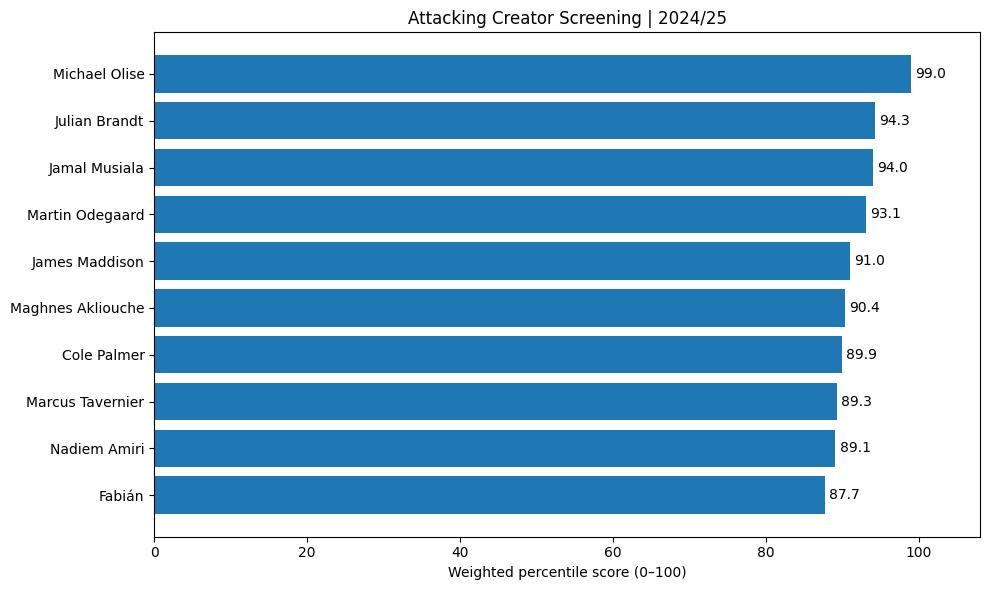

In [28]:

# Final screening group: minimum 1,800 minutes

plot_data = regulars.head(10).sort_values(
    'screening_score_1800'
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data['player_name'],
    plot_data['screening_score_1800']
)

ax.bar_label(bars, fmt='%.1f', padding=3)

ax.set_xlim(0, 108)
ax.set_xlabel('Weighted percentile score (0–100)')
ax.set_title(
    'Attacking Creator Screening | 2024/25'
)

plt.tight_layout()
plt.show()


## 9. Final Scouting Shortlist — Robustness Check

In [29]:

# Compare all three scouting strategies
# using the same 1,800+ minute player group

robust = regulars.copy()

for profile_name, weights in profiles.items():
    robust[profile_name] = (
        sum(
            robust[f'{metric}_percentile'] * weight
            for metric, weight in weights.items()
        ) * 100
    ).round(1)

    robust[f'{profile_name}_rank'] = (
        robust[profile_name]
        .rank(ascending=False, method='min')
        .astype(int)
    )

rank_columns = [
    f'{name}_rank' for name in profiles
]

# How many strategies place each player in the top 10?
robust['top10_appearances'] = (
    robust[rank_columns] <= 10
).sum(axis=1)

robust['average_rank'] = (
    robust[rank_columns].mean(axis=1).round(1)
)

# Sort by consistency across all three strategies
shortlist = robust.sort_values(
    ['top10_appearances', 'average_rank', 'minutes'],
    ascending=[False, True, False]
)

display(
    shortlist[
        ['player_name', 'clubs', 'minutes',
         'Balanced_rank',
         'Creation-first_rank',
         'Goal-threat emphasis_rank',
         'top10_appearances',
         'average_rank']
    ].head(12).reset_index(drop=True)
)


,player_name,clubs,minutes,Balanced_rank,Creation-first_rank,Goal-threat emphasis_rank,top10_appearances,average_rank
0,Michael Olise,Bayern Munich,2370.0,1,1,1,3,1.0
1,Julian Brandt,Borussia Dortmund,2354.0,2,2,6,3,3.3
2,Jamal Musiala,Bayern Munich,1822.0,3,7,2,3,4.0
3,Martin Odegaard,Arsenal,2343.0,4,4,7,3,5.0
4,James Maddison,Tottenham,1851.0,5,8,3,3,5.3
5,Cole Palmer,Chelsea,3228.0,7,3,8,3,6.0
6,Maghnes Akliouche,Monaco,2419.0,6,9,4,3,6.3
7,Marcus Tavernier,Bournemouth,1930.0,8,13,5,2,8.7
8,Nadiem Amiri,Mainz 05,2501.0,9,6,16,2,10.3
9,Fabián,Paris Saint Germain,1911.0,10,21,9,2,13.3


## 10. Scouting Report — Findings and Recommendations

### Objective

Identify attacking players who merit closer evaluation based on their 2024/25 chance-creation and goal-threat statistics.

### Analysis

The initial screening produced 282 player-league records with at least 1,200 minutes played. Increasing the threshold to 1,800 minutes reduced the group to 174 records.

Players were ranked using four per-90 metrics: expected assists, key passes, non-penalty expected goals, and expected goals buildup.

Three scoring models were tested, each assigning different importance to creativity and scoring threat. Seven players appeared in the top 10 under all three models.

### Findings

**Michael Olise — Performance benchmark**

Olise finished first in every model. He recorded 0.543 expected assists and 0.381 non-penalty expected goals per 90 minutes across 2,370 minutes.

His results stand out regardless of whether the model prioritizes creating chances or scoring opportunities. He provides a useful performance benchmark, although that does not establish him as a realistic transfer target.

**Julian Brandt and Martin Ødegaard — Creative profiles**

Brandt finished second in both the Balanced and Creation-first models, while Ødegaard ranked fourth in both.

Their consistency makes them useful reference players when evaluating candidates for a chance-creation-focused role.

**Maghnes Akliouche — Further scouting candidate**

Akliouche played 2,419 minutes and recorded 0.316 xA and 0.280 npxG per 90. He finished fourth in the Goal-threat model and remained in the top 10 across all three strategies.

His profile merits closer video and tactical analysis to determine how his production translates to a specific team role.

### Recruitment Recommendation

I would use the seven players who consistently ranked in the top 10 as the initial reference group, rather than select one target based on the highest composite score.

The next step would be to compare these players against the recruiting club's positional requirements, playing style, and financial constraints.

Olise provides the strongest overall statistical benchmark. Brandt and Ødegaard offer useful creative comparisons, while Akliouche deserves further investigation as a player with a balanced attacking profile in this dataset.

### Limitations

The model evaluates attacking output but does not fully account for defensive responsibilities, tactical roles, league strength, or team possession patterns.

The metric weights were selected for the analysis rather than validated against recruitment outcomes. Rankings are therefore useful for screening, not predicting transfer success.

Contract status, transfer costs, wages, injury history, and detailed event or video analysis would be needed before recommending an acquisition.

### Final Assessment

This analysis reduces a broad player pool to a more focused group for further evaluation. It also demonstrates how changing the playing-time threshold and recruitment priorities affects the results.

The most defensible outcome is a transparent scouting process that helps prioritize further investigation—not a claim that the highest-ranked player is automatically the best signing.